# Zonal means of ocean heat uptake

The data shown in `OHC_plots.ipynb`, resolved by latitude. Plotting and loading functions live in `ohc_cases.py`.

**Conventions.** Data run 2035–2069. OHC change per latitude band is the **2069 annual mean minus the 2035 annual
mean**, the same change as the end point of the time series in `OHC_plots.ipynb` figure 1, so the bands of each
condition add up to that figure's end label (checked below). Annual means weight each month by its length;
ensembles are member means. Bands are 5° wide and are built on the native POP grid: every ocean cell's heat
content per m² times its area, summed over the cells whose T-point latitude falls in the band (no regridding).
Each member's bands are checked to sum to the change in its `OHC_global_mean` × ocean area. Units are ZJ (10²¹ J)
per band, so a band's value is the total heat it gained, not a per-area density.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "/glade/work/wkamp/GEO/PRISM/PRISM/OHC_levels")
import ohc_cases as oc

plt.rcParams.update(oc.STYLE)

START, END = 2035, 2069
ZONAL_BASE, ZONAL_FINAL = (START, START), (END, END)  # change = mean over ZONAL_FINAL minus mean over ZONAL_BASE;
                                                      # (2035, 2039), (2065, 2069) gives the scatter-plot periods
LAT_EDGES = np.arange(-90, 91, 5)                     # 5° latitude bands

ARISE_CONDITIONS = {      # display name: (family, experiment), as in OHC_plots.ipynb
    "SSP2-4.5": ("CESM2_WACCM_SSP2-4.5", "CMIP6-SSP2-4.5-WACCM"),
    "ARISE-1.5": ("ARISE_SAI", "SSP245-TSMLT-GAUSS-DEFAULT"),
    "ARISE-1.0": ("ARISE-1.0", "SSP245-TSMLT-GAUSS-LOWER-0.5"),
}

In [2]:
# Members and global time series exactly as in OHC_plots.ipynb (duplicates dropped by load_experiments), then the
# latitude-band change for every member.
cases = oc.discover_cases()
labels = cases.experiment.map(oc.experiment_label)
cases = cases[[(f, l) in set(ARISE_CONDITIONS.values()) for f, l in zip(cases.family, labels)]]
experiments = oc.load_experiments(cases, depth=None)
area_m2 = oc.ocean_cell_area_m2()

data = {}
for name, (family, label) in ARISE_CONDITIONS.items():
    key = oc.find_experiment(experiments, family, label)
    zonal = oc.zonal_band_change(cases, experiments, key, ZONAL_BASE, ZONAL_FINAL, edges=LAT_EDGES, area_m2=area_m2)
    data[name] = dict(key=key, ohc=oc.change_since(experiments[key], START, END), zonal=zonal)

## 1. Ocean heat uptake by latitude and depth layer: SSP2-4.5, ARISE-1.5 and ARISE-1.0

Figure 1 of `OHC_plots.ipynb` turned on its side. For each 5° latitude band, the total OHC gained from 2035 to
2069 (black outline) with the part held in each depth layer as stacked bars; layers that lose heat stack left of
zero. Gray outlines are the members' min–max of the band total. The three panels share both axes.

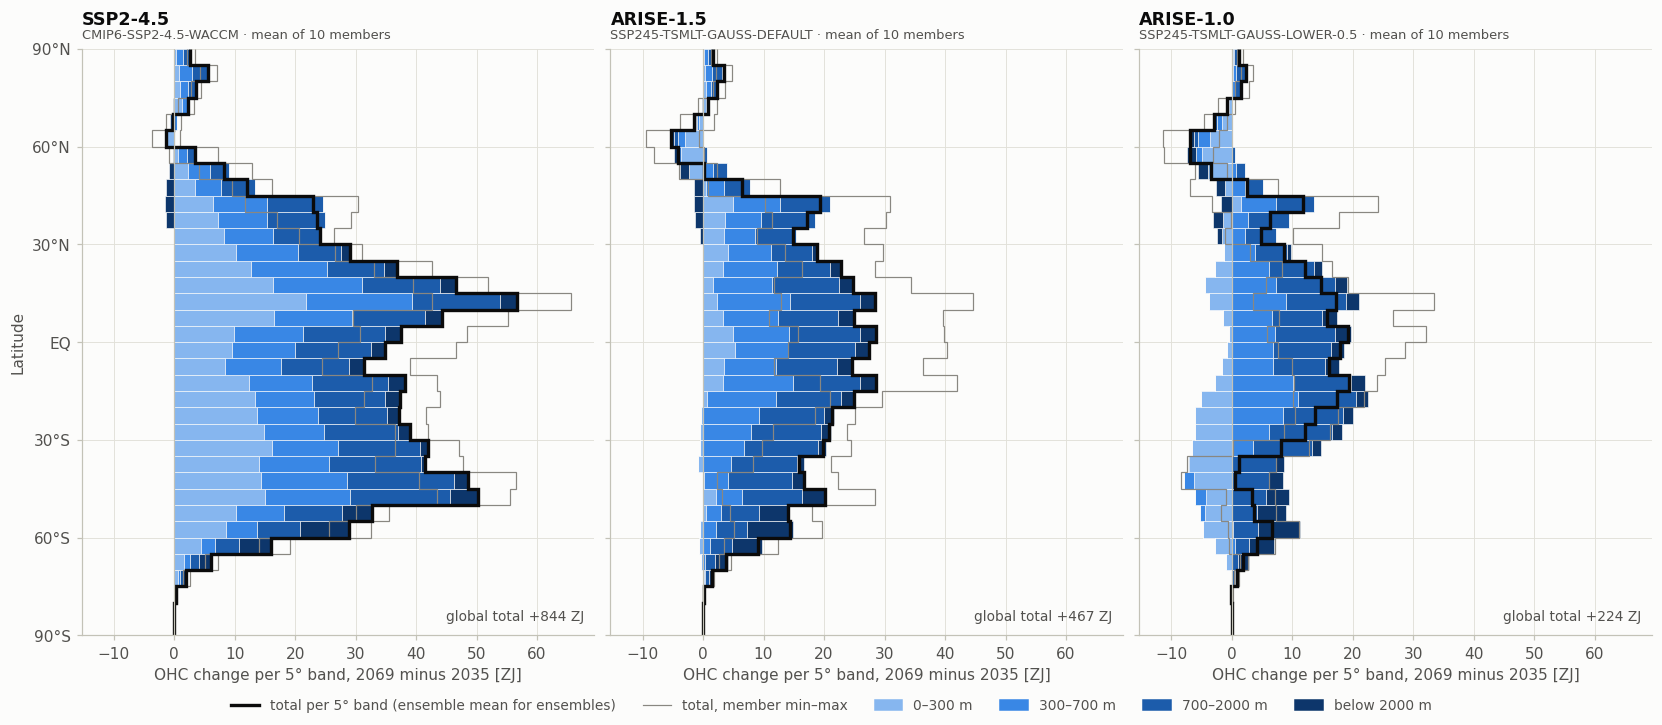

In [3]:
period = f"{ZONAL_FINAL[0]}" if ZONAL_FINAL[0] == ZONAL_FINAL[1] else f"{ZONAL_FINAL[0]}–{ZONAL_FINAL[1]}"
since = f"{ZONAL_BASE[0]}" if ZONAL_BASE[0] == ZONAL_BASE[1] else f"{ZONAL_BASE[0]}–{ZONAL_BASE[1]}"
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
oc.plot_zonal_layer_grid(fig, axes, [(name, data[name]["key"], data[name]["zonal"]) for name in ARISE_CONDITIONS],
                         xlabel=f"OHC change per 5° band, {period} minus {since} [ZJ]")
plt.show()

**Check and hemispheric split.** The band total summed over latitude, against the end point of `OHC_plots.ipynb`
figure 1 (the global time series, ensemble mean, change since 2035), and the share gained in each hemisphere.

In [4]:
rows = {}
for name, d in data.items():
    z = d["zonal"].mean("member") / oc.ZJ
    total = z.sel(ohc_depth=-1)
    rows[name] = {
        "members": d["zonal"].sizes["member"],
        "Σ bands [ZJ]": float(total.sum("lat")),
        f"figure 1 end, {END} since {START} [ZJ]": float(d["ohc"].sel(ohc_depth=-1, year=END).mean()) / oc.ZJ,
        "NH [ZJ]": float(total.where(total.lat > 0).sum()),
        "SH [ZJ]": float(total.where(total.lat < 0).sum()),
        "worst band-sum mismatch": d["zonal"].attrs["max_relative_mismatch"],
    }
check = pd.DataFrame(rows).T.astype({"members": int})
display(check.style.format("{:+.1f}", subset=[c for c in check if "ZJ" in c])
        .format("{:.1e}", subset=["worst band-sum mismatch"]))

,members,Σ bands [ZJ],"figure 1 end, 2069 since 2035 [ZJ]",NH [ZJ],SH [ZJ],worst band-sum mismatch
SSP2-4.5,10,+844.0,+844.0,+358.1,+485.9,1.4e-14
ARISE-1.5,10,+467.0,+467.0,+203.9,+263.1,1.8e-13
ARISE-1.0,10,+224.1,+224.1,+97.4,+126.7,1.2e-12


## 2. Ocean-mean heat uptake by latitude and depth layer: SSP2-4.5, ARISE-1.5 and ARISE-1.0

Figure 1 divided by each band's ocean area: the zonal mean over ocean only (land excluded), in GJ m⁻² (10⁹ J per
m² of ocean surface). Where figure 1 is dominated by the wide, ocean-rich tropical and Southern Ocean bands, this
shows how much heat each m² of ocean took up. Bands with little ocean (the Arctic, 65–80°S) rest on few cells and are
noisier. The corner note is the global ocean mean (global total / ocean area), which equals the band values averaged
with ocean-area weights.

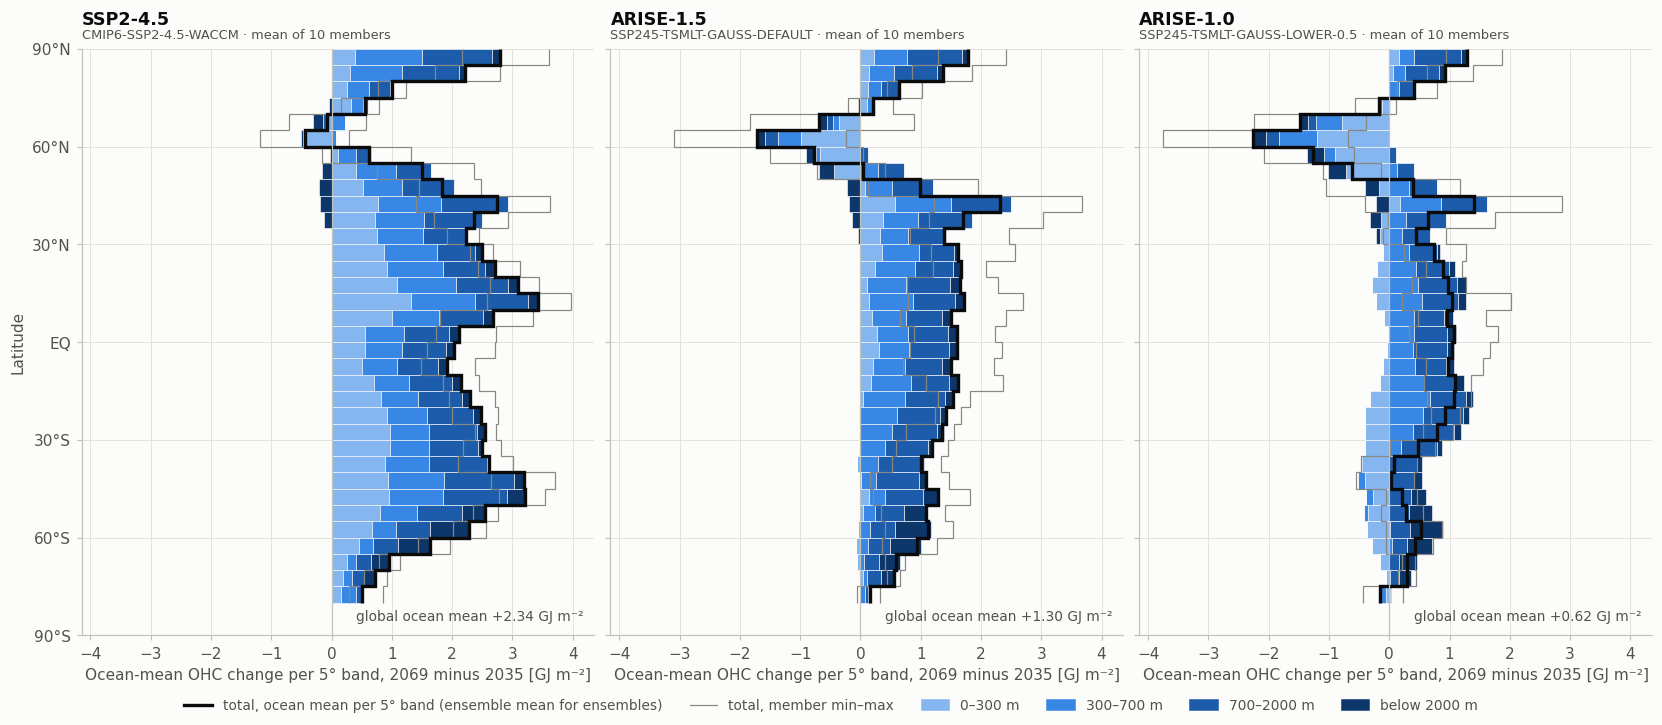

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
oc.plot_zonal_layer_grid(fig, axes, [(name, data[name]["key"], data[name]["zonal"]) for name in ARISE_CONDITIONS],
                         xlabel=f"Ocean-mean OHC change per 5° band, {period} minus {since} [GJ m⁻²]", per_area=True)
plt.show()

## 3. Top-of-atmosphere radiative fluxes by latitude: ASR, OLR, EEI and iEEI

Annual band values written by `zonal_toa_fluxes.py` (run with `zonal_toa_fluxes.pbs`) from monthly lat×lon FSNT
(ASR) and FLNT (OLR), for the same 10 members per condition as the OHC. EEI = ASR − OLR at the top of the model, as in
`J04_CESM_EEI_timeseries_multiensemble.py`; positive means the band gains energy. iEEI is EEI integrated over time,
the energy the band gained. ASR, OLR and EEI are **2035–2069 means**; iEEI is the **2035–2069 total** (1 January 2035
to 31 December 2069, every month weighted by its length). The OHC change in sections 1–2 is the 2069 annual mean minus
the 2035 annual mean, so the two cover slightly different intervals.

**Spatial area.** The atmosphere and the ocean are on different grids, so the flux bands are not built like the OHC
bands:
* **OHC (POP grid):** sums ocean cells by their T-point latitude; rows are 0.2–0.5° apart, so whole-cell binning
  stays close to the band edges. Per-area values divide by the band's **ocean** area.
* **Fluxes (CAM grid):** rows are 0.94° apart, so binning whole rows by center would give some 5° bands 5 rows and
  others 6, making band areas and totals 8–13% wrong. Instead each CAM row is split between the bands it straddles
  by area (row edges from the Gaussian weights `gw`), so each band's area is the exact spherical band area
  2πR²(sin φ₂ − sin φ₁), with CAM's R = 6.37122×10⁶ m. Per-area values are means over the **whole band, land and
  ocean**.

So the band totals in section 3 (PW, ZJ) can be compared with section 1. The band means in section 4 are per m² of
Earth surface, not per m² of ocean as in section 2. A zonal TOA imbalance is not expected to match the zonal OHC
change band by band: atmospheric and oceanic heat transport move energy between latitudes, so the two agree only in
the global integral.

In [6]:
# Annual band values (condition, member, year, lat). load_zonal_toa checks that every band area is the exact
# spherical band area (whole band, land + ocean, CAM's Earth radius) -- not the POP ocean area of the OHC bands.
toa = oc.load_zonal_toa()
TOA_EDGES = np.asarray(toa.attrs["lat_edges"])
EARTH_AREA = toa.attrs["earth_area_m2"]
PW = 1e15
assert np.array_equal(TOA_EDGES, LAT_EDGES), "flux and OHC bands differ"
toa = toa.sel(year=slice(START, END))
assert toa.sizes["year"] == END - START + 1 and not any(bool(toa[v].isnull().any()) for v in toa.data_vars)
for name, d in data.items():
    assert list(toa.sel(condition=name).member.values) == list(d["zonal"].member.values), f"{name}: members differ"

TOA_SPECS = {  # label, color, units/format for band totals and band means; iEEI is summed over years, the rest averaged
    "ASR":  dict(label="ASR (absorbed shortwave, FSNT)", color=oc.PALETTE[1], tot=(PW, "PW", "{:.1f}"), per=(1, "W m⁻²", "{:.1f}")),
    "OLR":  dict(label="OLR (outgoing longwave, FLNT)", color=oc.PALETTE[6], tot=(PW, "PW", "{:.1f}"), per=(1, "W m⁻²", "{:.1f}")),
    "EEI":  dict(label="EEI = ASR − OLR", color=oc.PALETTE[2], tot=(PW, "PW", "{:+.2f}"), per=(1, "W m⁻²", "{:+.2f}")),
    "iEEI": dict(label="iEEI (energy gained)", color=oc.PALETTE[0], tot=(oc.ZJ, "ZJ", "{:+.0f}"), per=(oc.GJ, "GJ m⁻²", "{:+.2f}")),
}


def toa_period(var, kind, years=(START, END)):
    """Band value over the calendar years first..last [SI], (condition, member, lat): kind "total" (band total) or
    "mean" (band mean). iEEI is summed over the years, the other variables averaged."""
    da = toa[f"{var}_{kind}"].sel(year=slice(*years))
    assert da.sizes["year"] == years[1] - years[0] + 1, f"{var}: years {years} not all in the file"
    return da.sum("year") if var == "iEEI" else da.mean("year")


def plot_toa(var, per_area=False):
    """Section 1 (band totals) or section 2 (per_area: band means) figure for one flux variable."""
    spec = TOA_SPECS[var]
    how = f"{START}–{END} {'total' if var == 'iEEI' else 'mean'}"
    total = toa_period(var, "total")
    if per_area:
        scale, unit, fmt = spec["per"]
        values = toa_period(var, "mean") / scale
        xlabel = f"Band-mean {var} (land + ocean), {how} [{unit}]"
        note = "global mean " + fmt + " " + unit
        to_note = lambda glob: glob / EARTH_AREA / scale   # global mean = global total / Earth area
    else:
        scale, unit, fmt = spec["tot"]
        values = total / scale
        xlabel = f"{var} per 5° band, {how} [{unit}]"
        note = "global total " + fmt + " " + unit
        to_note = lambda glob: glob / scale
    items = [(name, data[name]["key"], values.sel(condition=name),
              to_note(float(total.sel(condition=name).mean("member").sum("lat")))) for name in ARISE_CONDITIONS]
    fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
    oc.plot_zonal_flux_grid(fig, axes, items, TOA_EDGES, xlabel, spec["color"], note,
                            "band mean" if per_area else "total")
    plt.show()

**Check: area treatment and global integrals.**
* *Σ band areas / Earth area* should be 1.
* The global ASR and OLR from the bands are compared, every member and year, with PRISM's
  `spatial_averages_data` global means (`spatial="G"`, the series J04 uses), which were computed independently from
  the CAM grid weights.
* The global iEEI is set against the OHC end point of `OHC_plots.ipynb` figure 1. They are not expected to be
  equal: they cover slightly different intervals, some energy goes into land, sea ice and the atmosphere, and the
  model does not conserve energy exactly.
* NH and SH give each hemisphere's share of iEEI.

In [7]:
rows = {}
for name, d in data.items():
    family, experiment = d["key"]
    t = toa.sel(condition=name)
    worst = 0.0
    for member in t.member.values:
        for var, cam in (("ASR", "FSNT"), ("OLR", "FLNT")):
            ref = oc.annual_mean(oc.load_case_ts(family, f"{experiment}.{member}", var=cam)).sel(year=slice(START, END))
            mine = t[f"{var}_total"].sel(member=member).sum("lat") / EARTH_AREA
            worst = max(worst, float(np.abs(mine.values - ref.values).max()))
    ieei = toa_period("iEEI", "total").sel(condition=name).mean("member") / oc.ZJ
    rows[name] = {
        "Σ band areas / Earth area": float(t["band_area_m2"].sum()) / EARTH_AREA,
        "max |ASR, OLR − PRISM G| [W m⁻²]": worst,
        "global EEI [W m⁻²]": float(toa_period("EEI", "total").sel(condition=name).mean("member").sum("lat")) / EARTH_AREA,
        f"global iEEI {START}–{END} [ZJ]": float(ieei.sum("lat")),
        f"OHC, figure 1 end [ZJ]": float(d["ohc"].sel(ohc_depth=-1, year=END).mean()) / oc.ZJ,
        "iEEI NH [ZJ]": float(ieei.where(ieei.lat > 0).sum()),
        "iEEI SH [ZJ]": float(ieei.where(ieei.lat < 0).sum()),
    }
check = pd.DataFrame(rows).T
display(check.style.format("{:+.1f}", subset=[c for c in check if "ZJ" in c])
        .format("{:+.3f}", subset=["global EEI [W m⁻²]"])
        .format("{:.1e}", subset=["max |ASR, OLR − PRISM G| [W m⁻²]"])
        .format("{:.12f}", subset=["Σ band areas / Earth area"]))

,Σ band areas / Earth area,"max |ASR, OLR − PRISM G| [W m⁻²]",global EEI [W m⁻²],global iEEI 2035–2069 [ZJ],"OHC, figure 1 end [ZJ]",iEEI NH [ZJ],iEEI SH [ZJ]
SSP2-4.5,1.000000000000,8.7e-07,+1.539,+866.7,+844.0,+563.2,+303.5
ARISE-1.5,1.000000000000,9.8e-07,+0.809,+455.4,+467.0,+460.0,-4.5
ARISE-1.0,1.000000000000,9.5e-07,+0.344,+194.0,+224.1,+347.7,-153.7


### 3a. Band totals

Figure 1 (section 1) for the radiative fluxes. For each 5° band:
* ASR, OLR and EEI show the band's total power, 2035–2069 mean, in PW (10¹⁵ W).
* iEEI shows the energy the band gained over 2035–2069, in ZJ, the same unit as section 1.

The black outline is the ensemble mean and gray outlines are the members' min–max. The corner note gives the global
total. Band totals scale with band area, which shrinks toward the poles as cos φ.

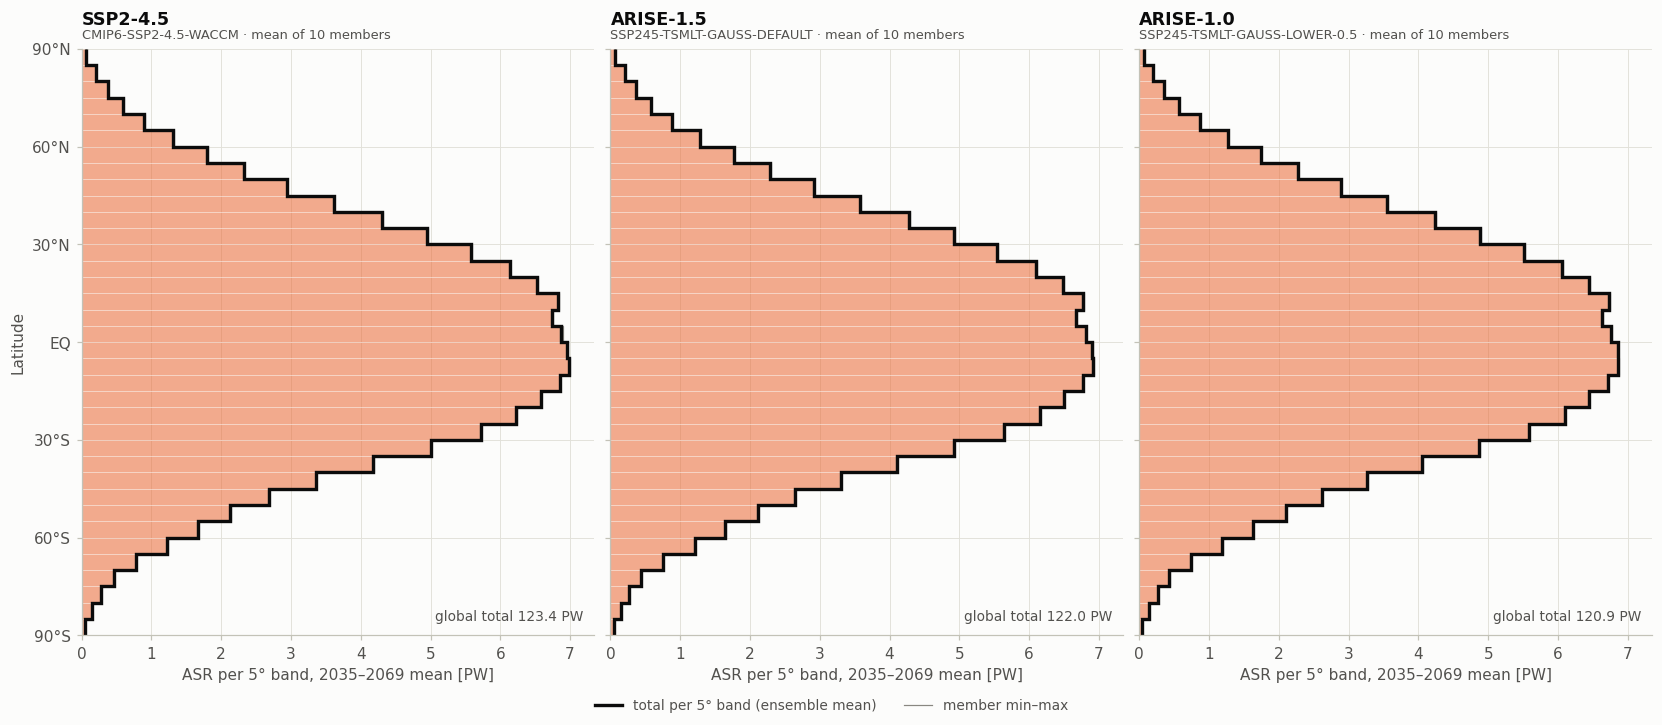

In [8]:
plot_toa("ASR")

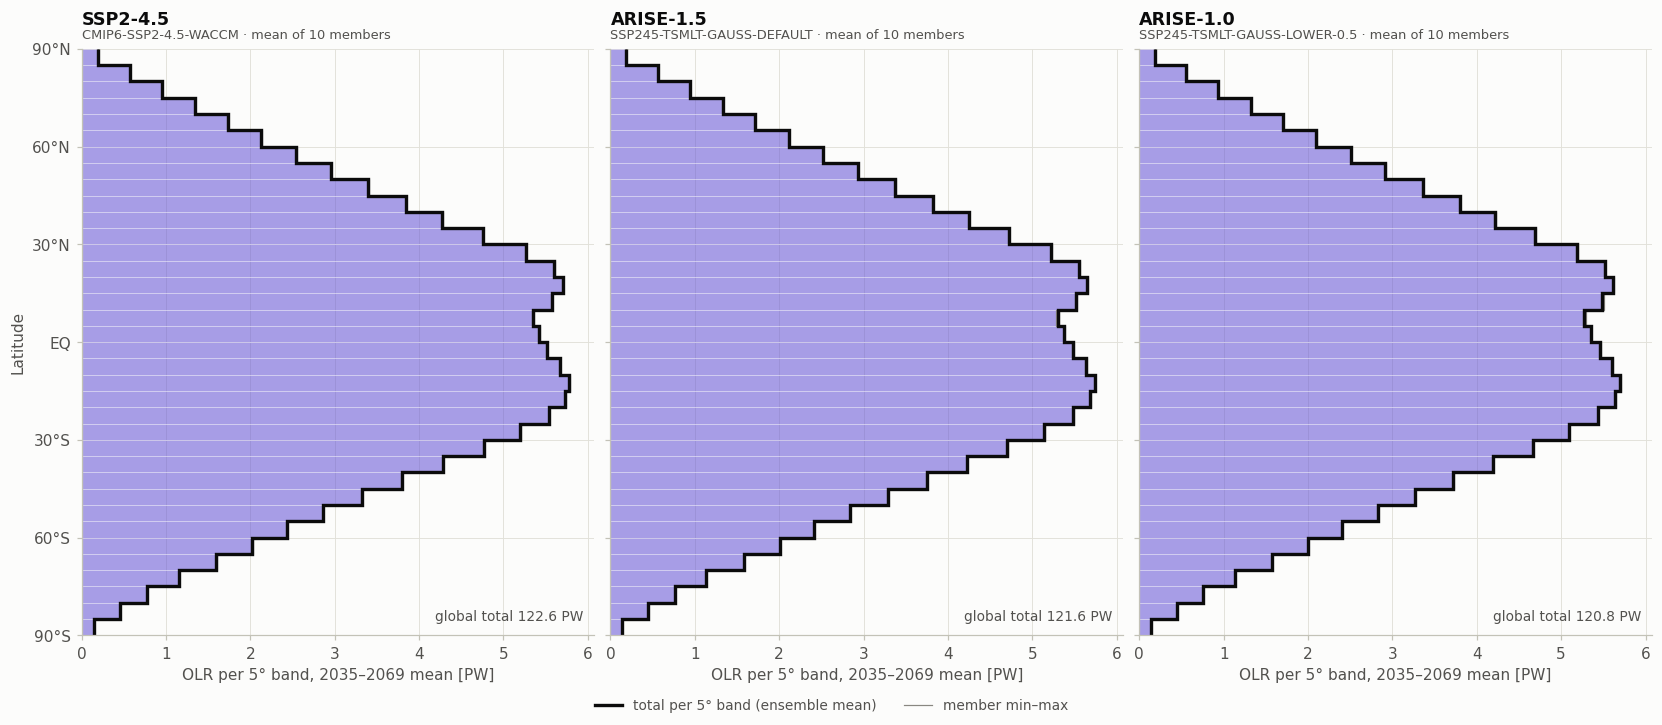

In [9]:
plot_toa("OLR")

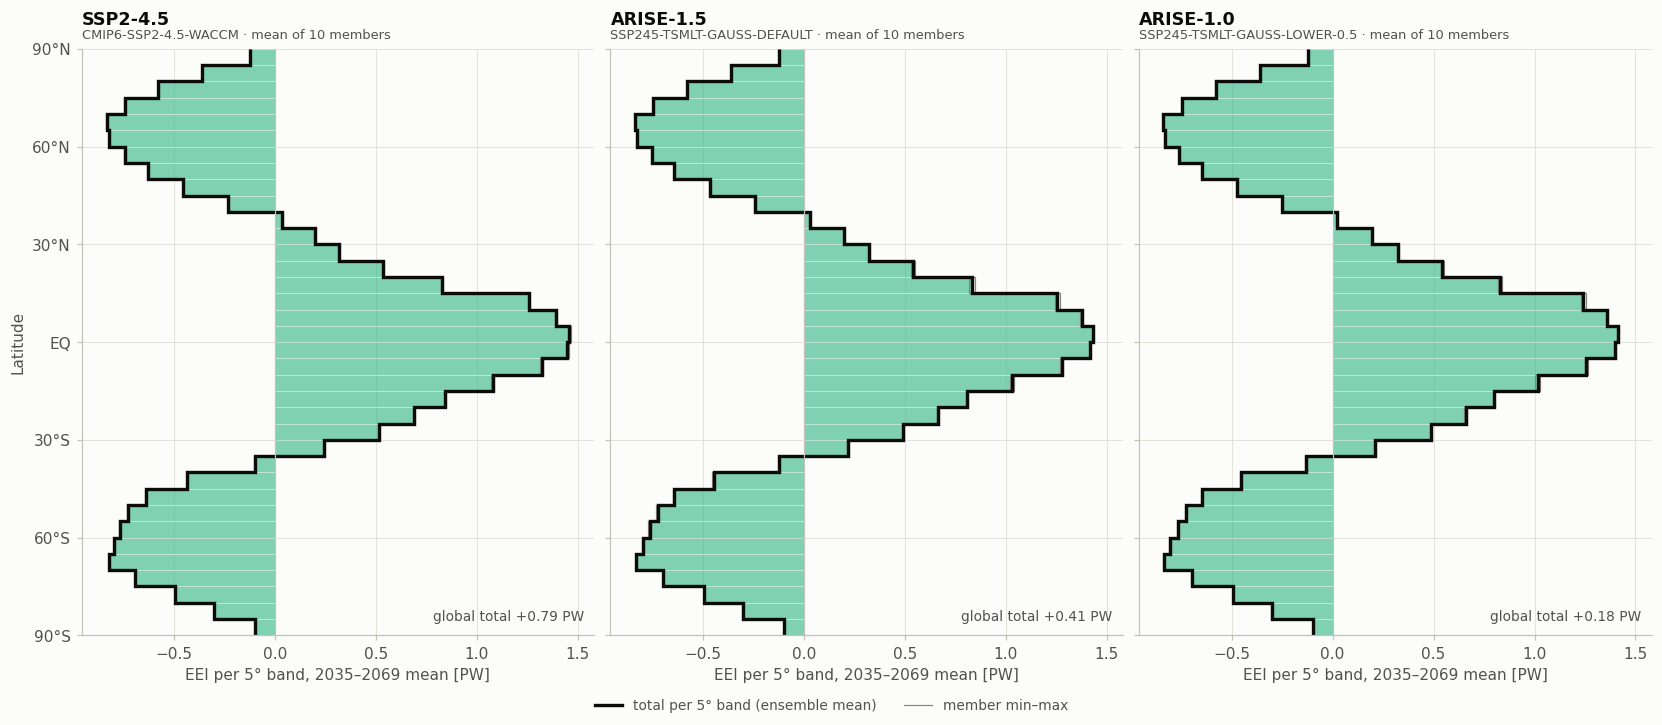

In [10]:
plot_toa("EEI")

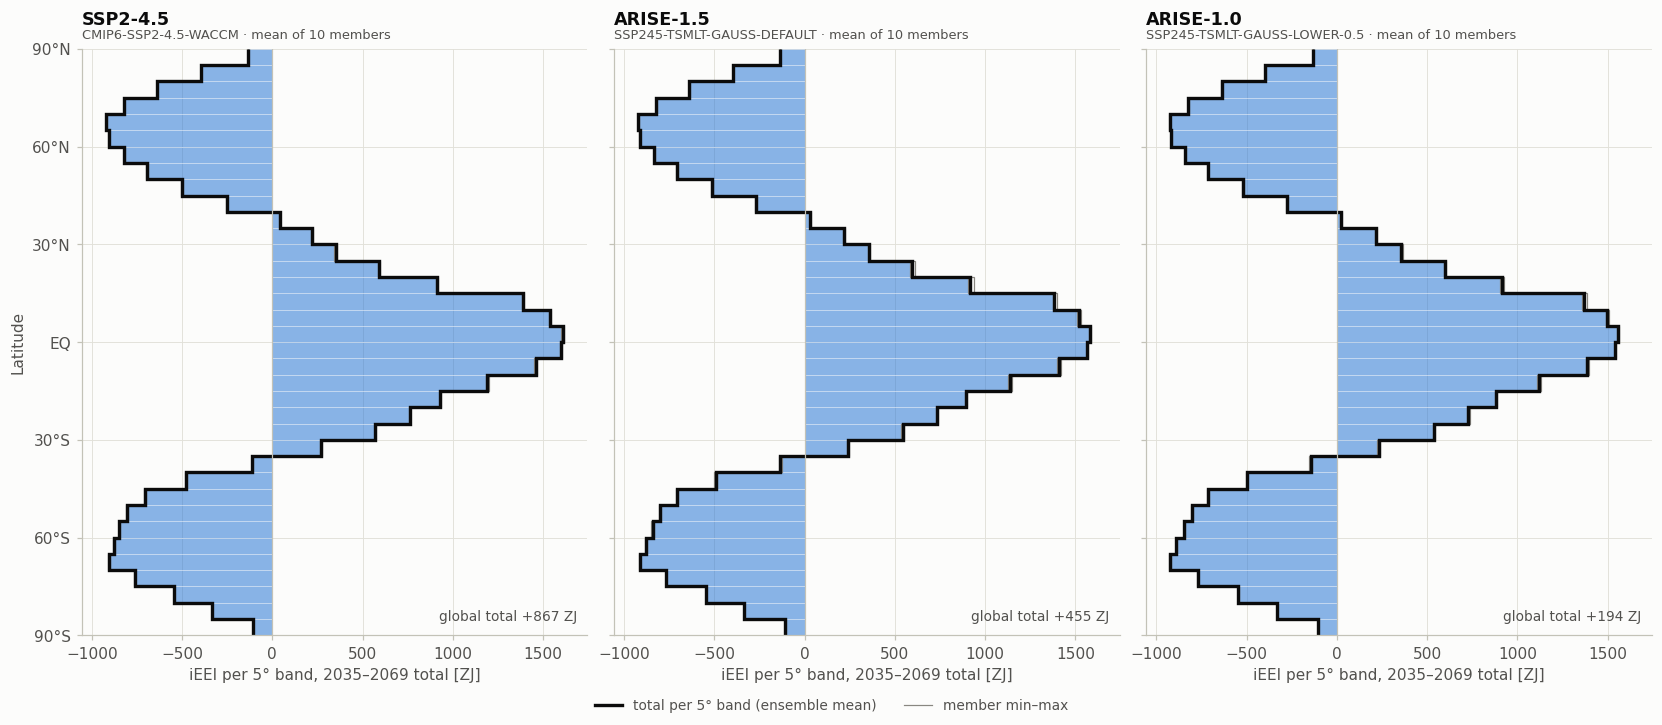

In [11]:
plot_toa("iEEI")

## 4. Band-mean radiative fluxes by latitude: ASR, OLR, EEI and iEEI

Figure 2 (section 2) for the radiative fluxes: each band total divided by the band's whole area, land and ocean. This
gives the zonal mean in W m⁻²; iEEI is in GJ m⁻² of Earth surface. Section 2 divides by ocean area only, so the two
sets of per-area values are not directly comparable. The corner note gives the global mean, which equals the global
total divided by Earth's area.

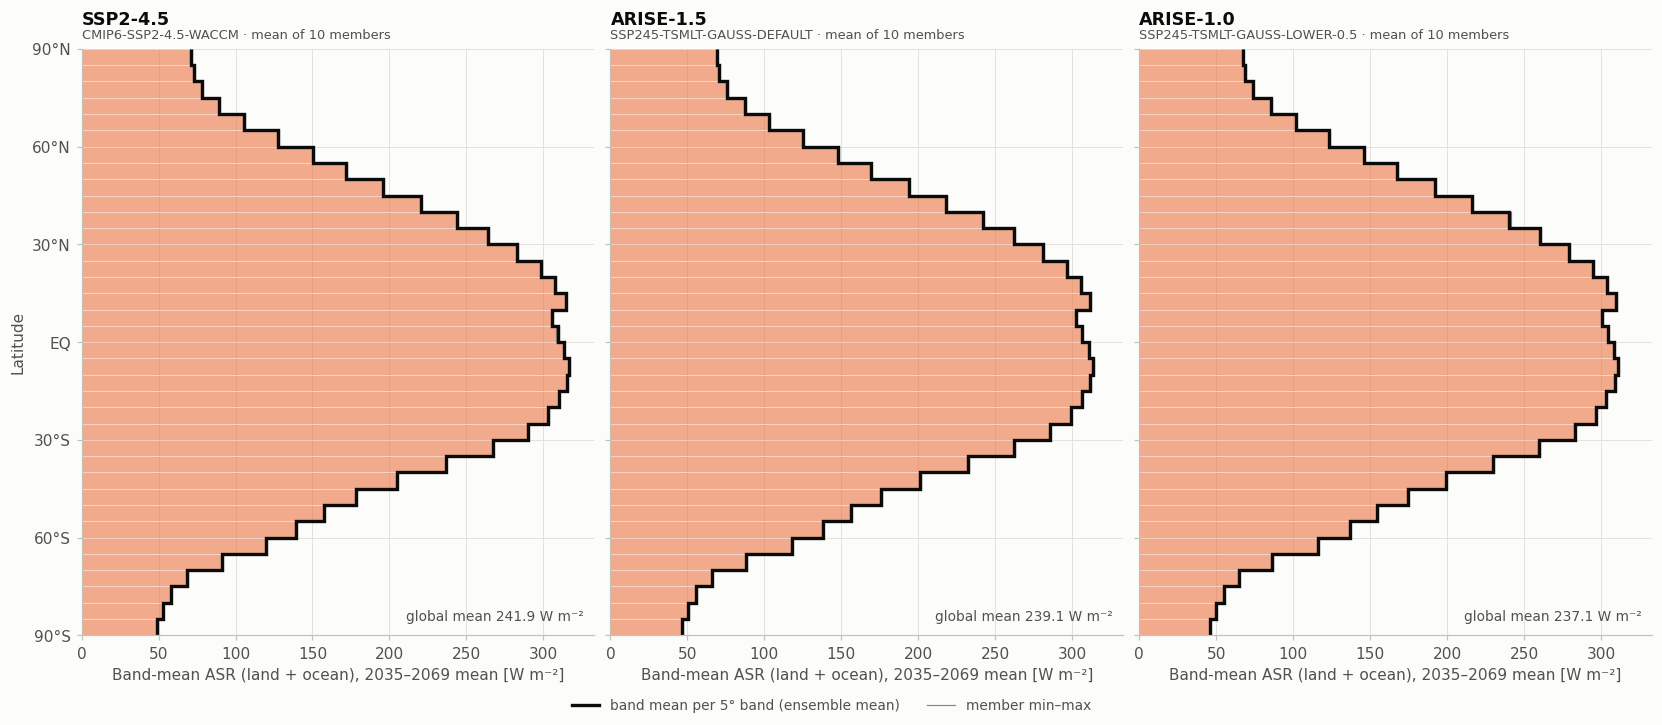

In [12]:
plot_toa("ASR", per_area=True)

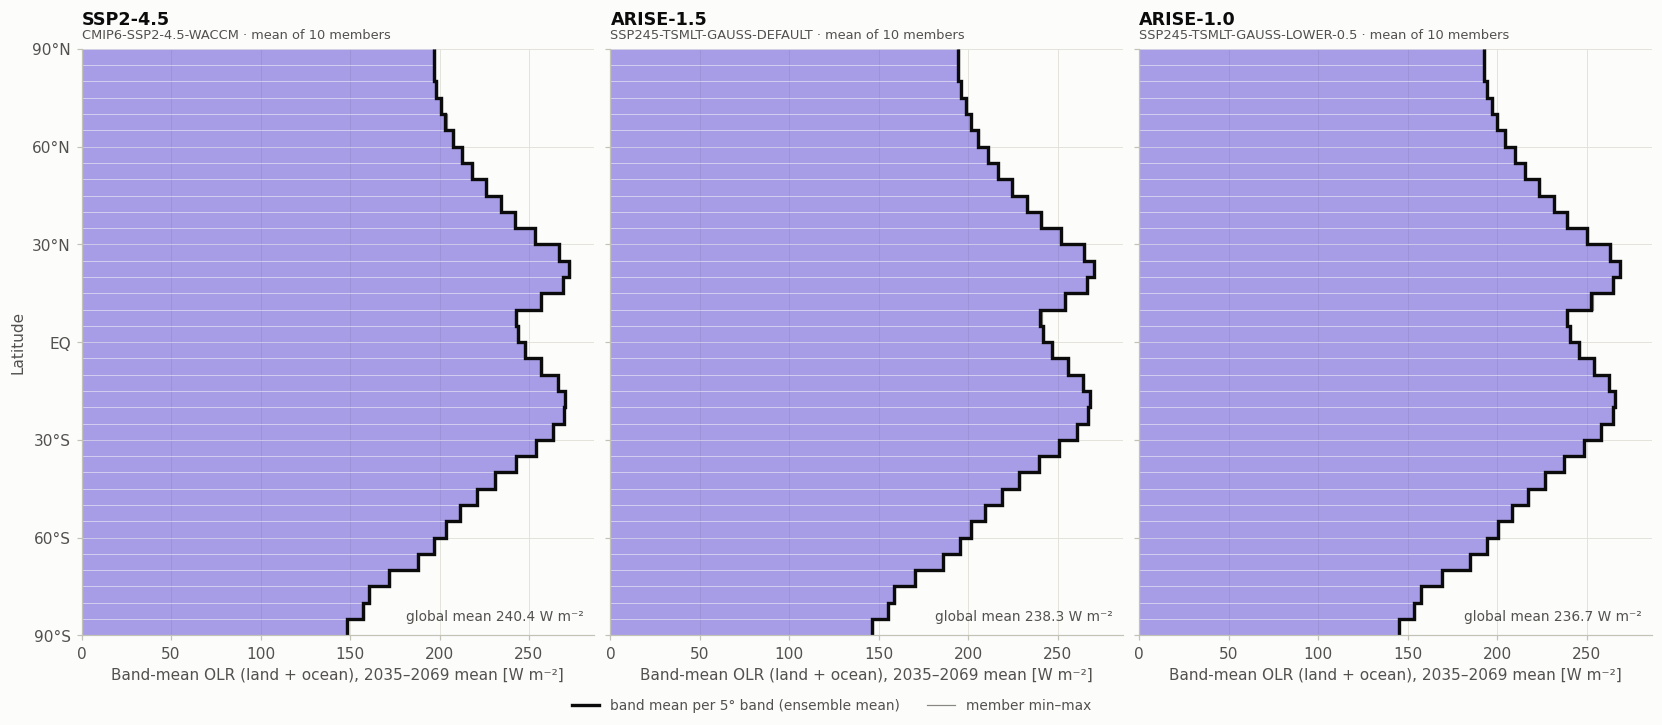

In [13]:
plot_toa("OLR", per_area=True)

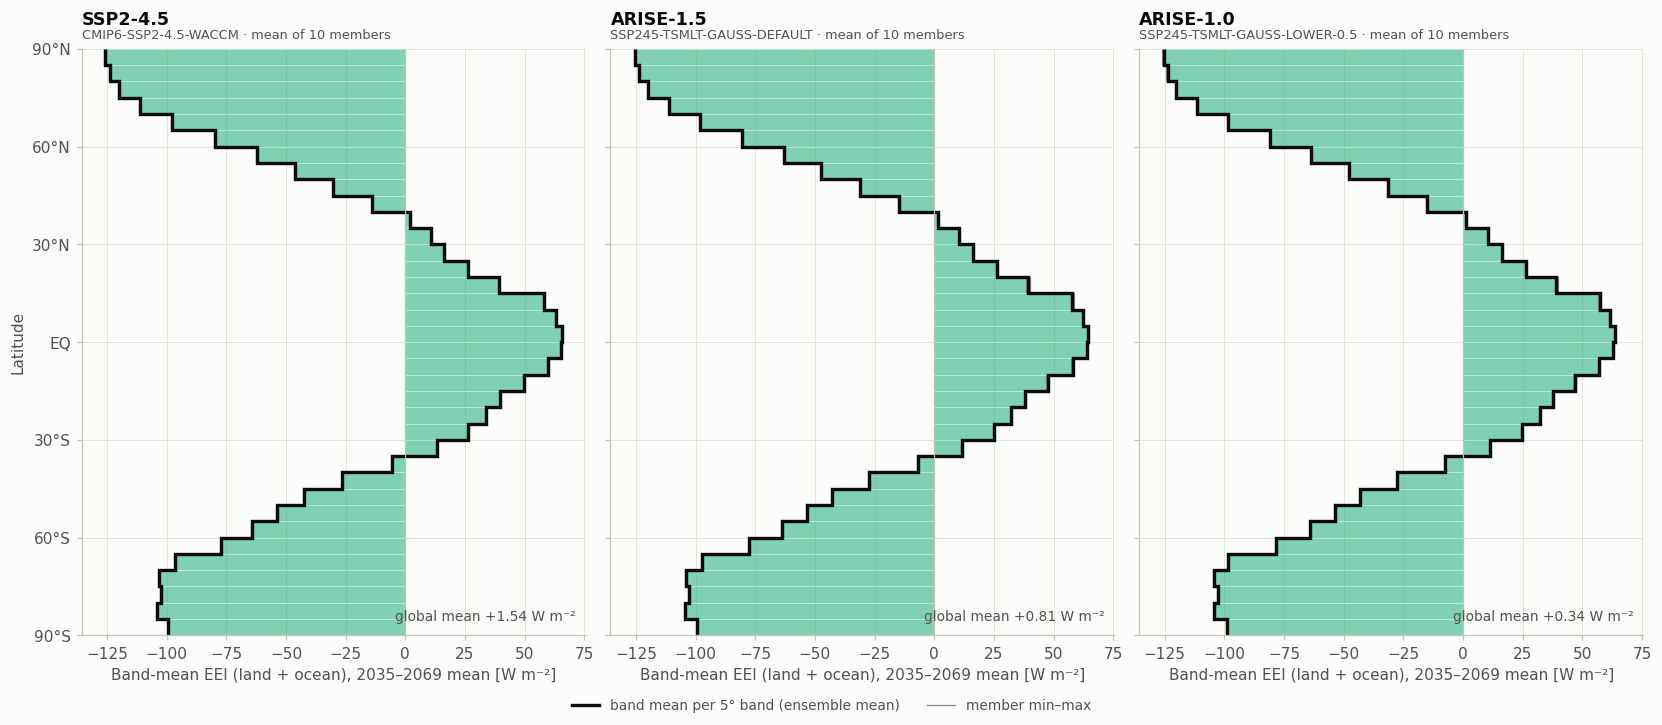

In [14]:
plot_toa("EEI", per_area=True)

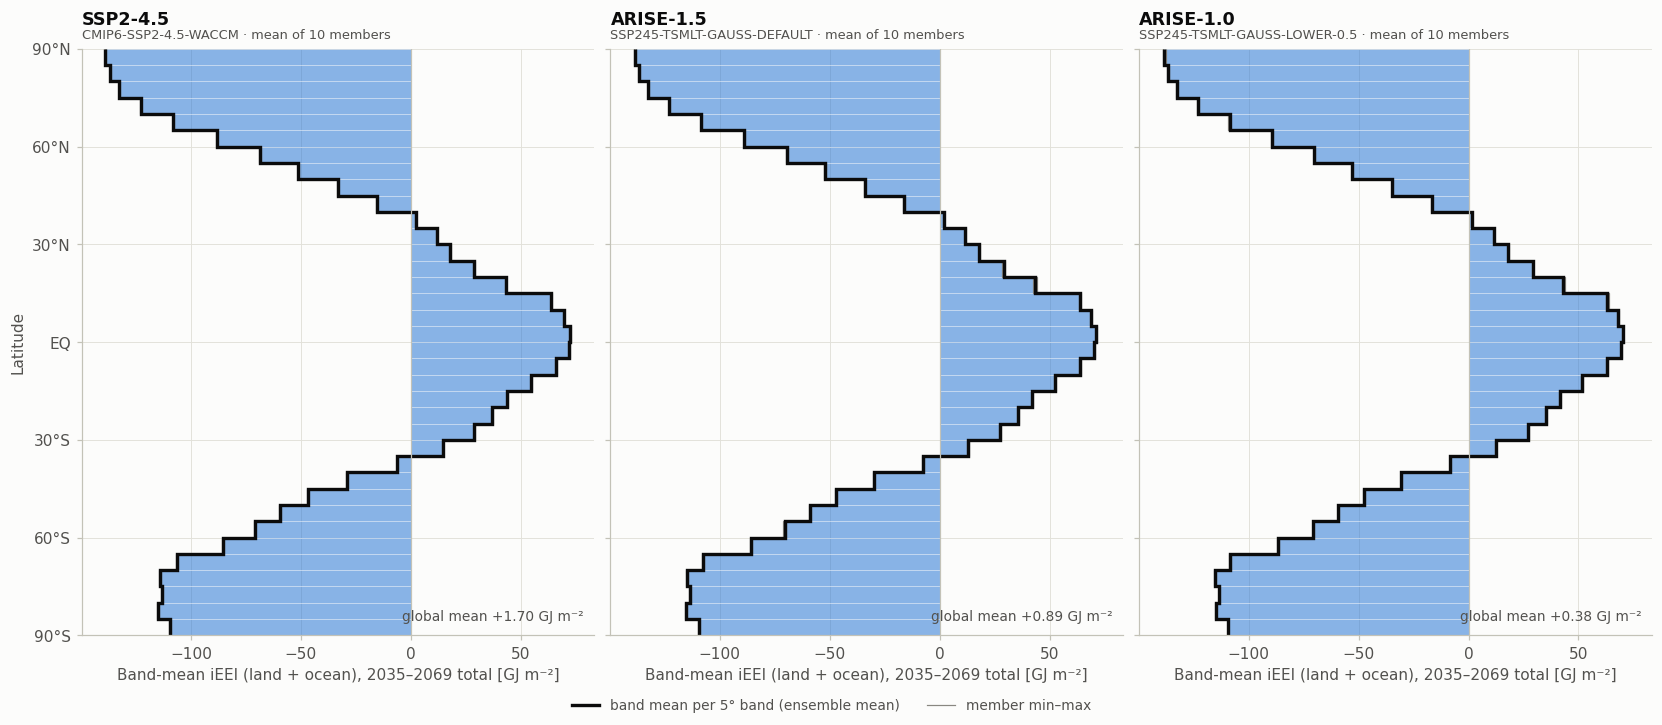

In [15]:
plot_toa("iEEI", per_area=True)

## 5. ASR, OLR and EEI by latitude: SSP2-4.5, ARISE-1.5 and ARISE-1.0 overlaid

Sections 3a and 4 with the conditions on one axis. One panel per variable. Each condition is a step outline (no fill)
of its ensemble mean, 2035–2069 mean, in the color used for that condition in `OHC_plots.ipynb`. Member spread is not
shown here (see sections 3a and 4). Panels share the latitude axis. Each variable has its own x axis, which includes
zero only when the values change sign. The note in each panel gives each condition's global value.

In [16]:
CONDITION_COLORS = {"SSP2-4.5": oc.PALETTE[0], "ARISE-1.5": oc.PALETTE[1], "ARISE-1.0": oc.PALETTE[2]}  # as in OHC_plots.ipynb


def _span(years):
    return f"{years[0]}" if years[0] == years[1] else f"{years[0]}–{years[1]}"


def plot_toa_comparison(per_area=False, variables=("ASR", "OLR", "EEI"), years=(START, END), baseline=None, **style):
    """The three conditions overlaid, one panel per variable: band totals (as in section 3a) or, with per_area,
    band means over the whole band, land + ocean (as in section 4), averaged over the calendar years first..last.
    baseline: (condition, (first, last)) to plot each condition minus that condition's ensemble mean over those
    years instead (section 6). style: passed to oc.plot_zonal_flux_comparison (notes, grid, zero_line, lw, fontsize)."""
    kind = "mean" if per_area else "total"
    panels = []
    for var in variables:
        spec = TOA_SPECS[var]
        scale, unit, fmt = spec["per" if per_area else "tot"]

        def band_and_global(yrs):   # plot units; global = global mean (per_area) or global total
            glob = toa_period(var, "total", yrs).mean("member").sum("lat") / (EARTH_AREA if per_area else 1)
            return toa_period(var, kind, yrs) / scale, glob / scale

        values, glob = band_and_global(years)
        if baseline is None:
            how = "total" if var == "iEEI" else "mean"
            what = f"Band-mean {var} (land + ocean)" if per_area else f"{var} per 5° band"
            xlabel = f"{what}, {_span(years)} {how} [{unit}]"
        else:
            assert var != "iEEI", "iEEI is a sum over the years, so periods of different length can't be differenced"
            base_name, base_years = baseline
            base_values, base_glob = band_and_global(base_years)
            values = values - base_values.sel(condition=base_name).mean("member").drop_vars("condition")
            glob = glob - base_glob.sel(condition=base_name).drop_vars("condition")
            what = f"zonal-mean {var} (land + ocean)" if per_area else f"zonal-total {var} per 5° latitude"
            xlabel, fmt = f"Δ {what} [{unit}]", "{:+.2f}"
        panels.append((spec["label"], xlabel, {name: values.sel(condition=name) for name in CONDITION_COLORS},
                       f"{fmt} {unit}", {name: float(glob.sel(condition=name)) for name in CONDITION_COLORS}))
    fig, axes = plt.subplots(1, len(variables), figsize=(15, 6.5), sharey=True, layout="constrained")
    note = "global mean" if per_area else "global total"
    suptitle = None
    if baseline is not None:
        note += " change"
        suptitle = (f"Each condition's {_span(years)} mean minus the {baseline[0]} {_span(baseline[1])} mean "
                    "(ensemble means)")
    oc.plot_zonal_flux_comparison(fig, axes, panels, TOA_EDGES, CONDITION_COLORS, note, suptitle=suptitle, **style)
    plt.show()

### 5a. Band totals

ASR, OLR and EEI as total power per 5° band, in PW (as in section 3a).

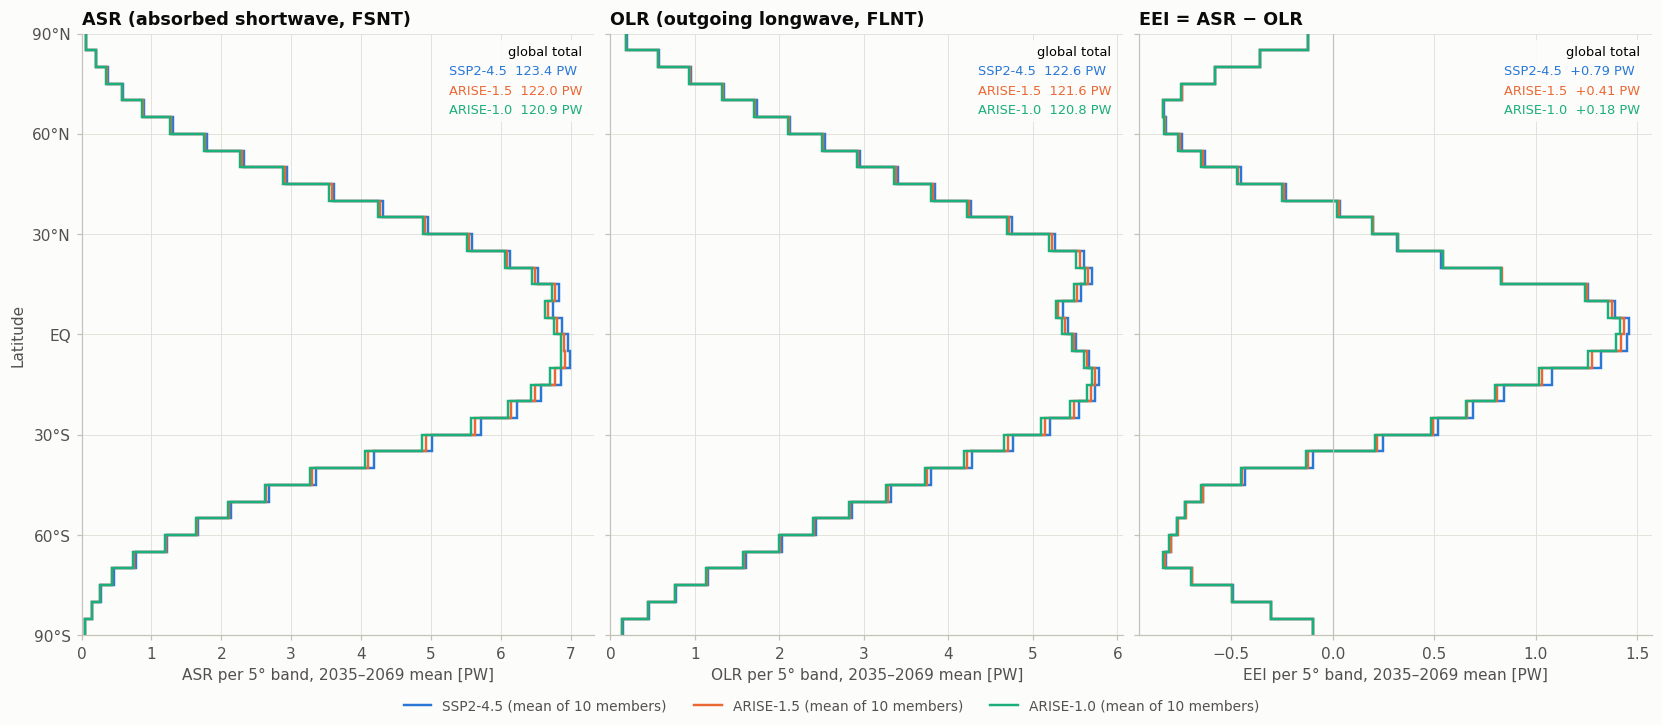

In [17]:
plot_toa_comparison()

### 5b. Band means

ASR, OLR and EEI as the band mean over land and ocean, in W m⁻² (as in section 4).

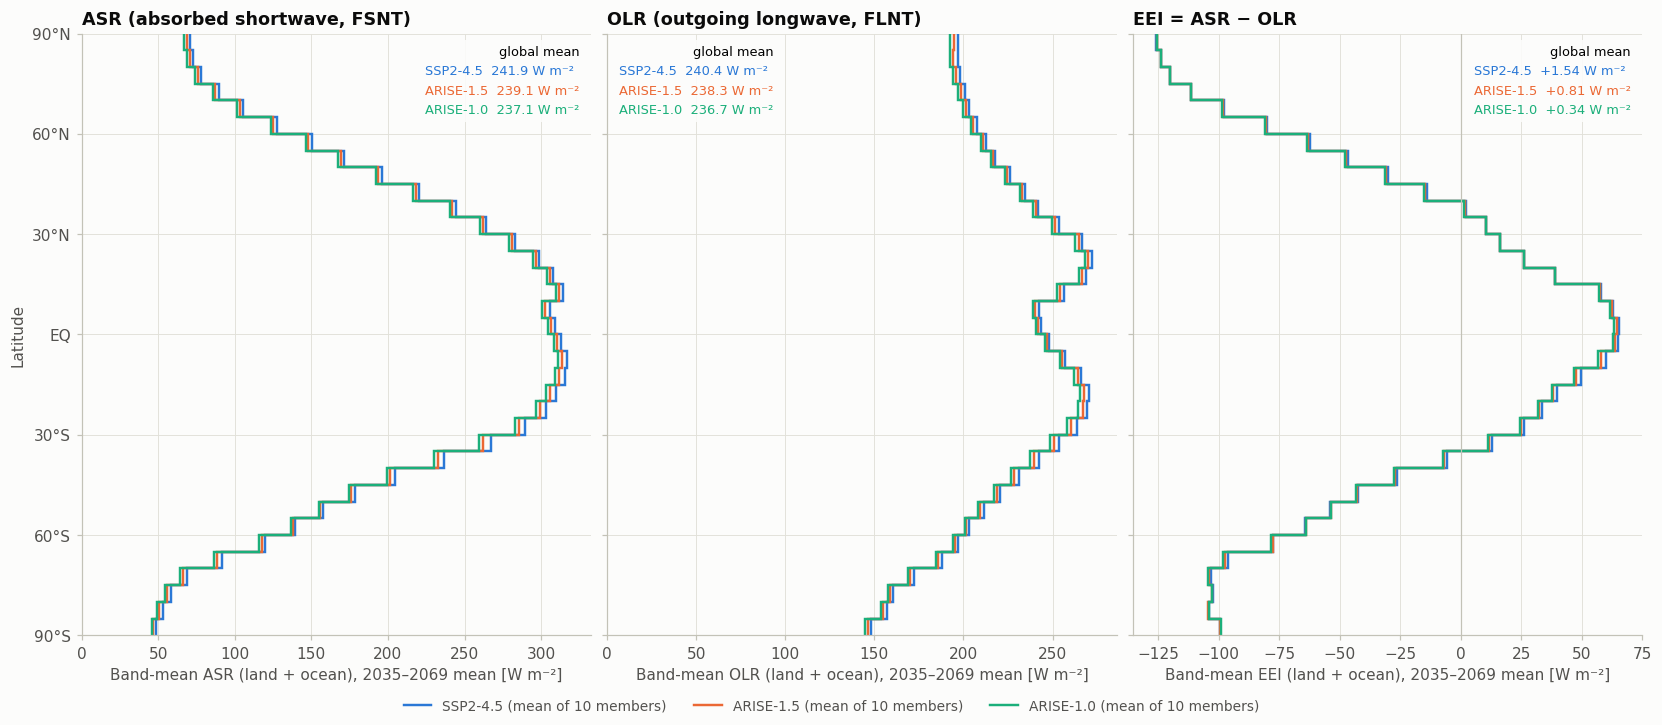

In [18]:
plot_toa_comparison(per_area=True)

## 6. Change in ASR, OLR and EEI by latitude: each condition's 2060–2069 against SSP2-4.5 in 2035–2044

Section 5 as a change from a common baseline: the **2060–2069 mean** of each condition minus the **2035–2044 mean of
SSP2-4.5**, both ensemble means (the convention of `oc.difference_maps`). The SSP2-4.5 line is its own change across
the period; the ARISE lines add what SAI changes on top. Positive ASR or EEI means the band absorbs or gains more than
SSP2-4.5 did in 2035–2044; positive OLR means it emits more. The note gives each condition's change in the global
value. iEEI is left out: it is a sum over years, so the change between periods isn't meaningful. Change `DIFF_YEARS`
or `DIFF_BASELINE` to compare other periods; `DIFF_STYLE` sets the look of the two figures (global-value
notes on or off, no grid, line width, text size).

In [22]:
DIFF_YEARS = (2060, 2069)                   # each condition's period, inclusive
DIFF_BASELINE = ("SSP2-4.5", (2035, 2044))   # subtracted from every condition
DIFF_STYLE = dict(
    notes=False,       # global-value note in each panel; set to False to hide it
    grid=False,       # no grid lines ...
    zero_line=True,   # ... only the x = 0 line
    lw=2.2,           # condition line width (section 5: 1.6)
    fontsize=13,      # every text except the panel titles (sections 1-5: 8.5-10)
)

### 6a. Band totals

Change in total power per 5° band, in PW (as in section 5a).

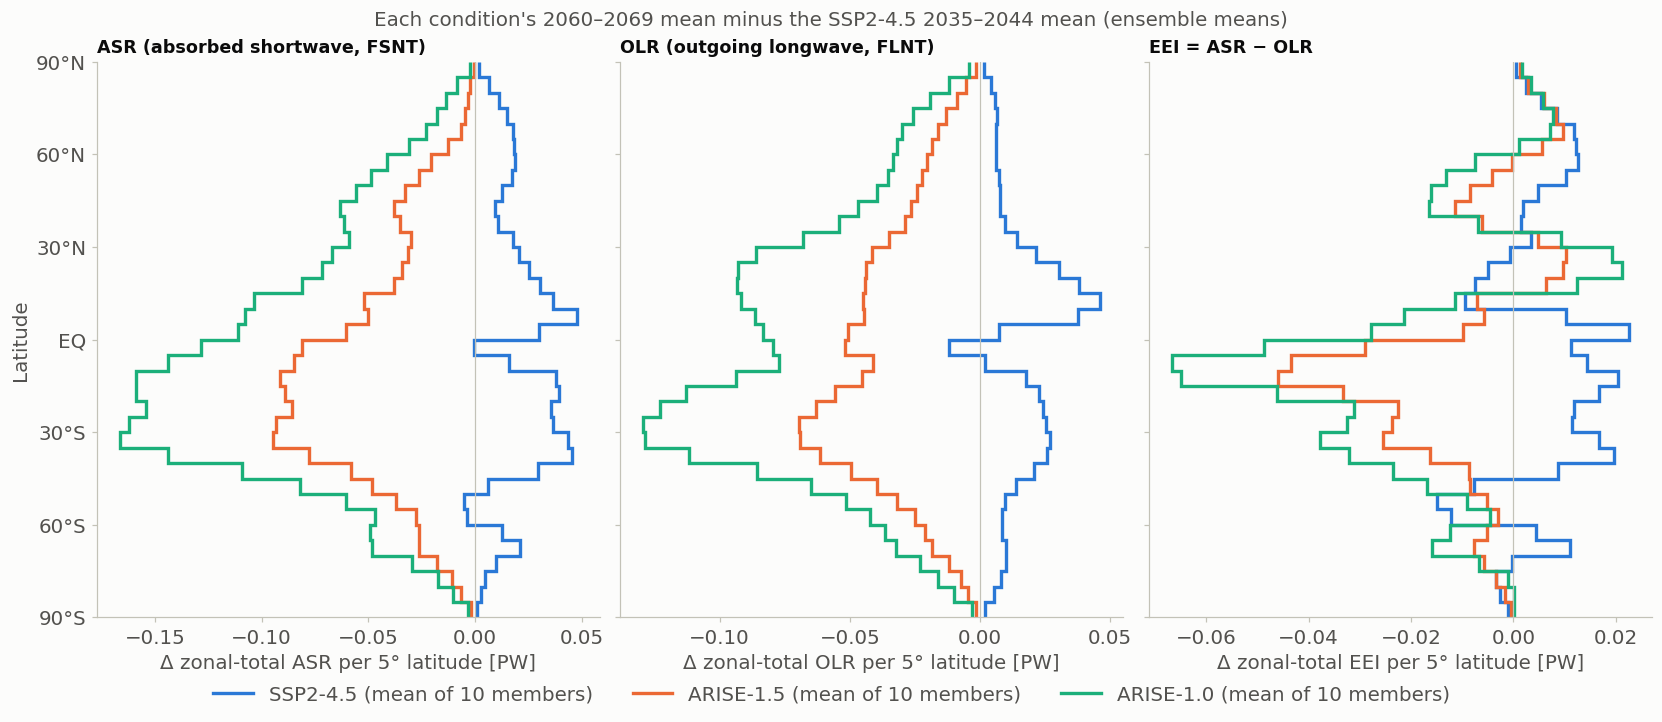

In [23]:
plot_toa_comparison(years=DIFF_YEARS, baseline=DIFF_BASELINE, **DIFF_STYLE)

### 6b. Band means

Change in the band mean over land and ocean, in W m⁻² (as in section 5b).

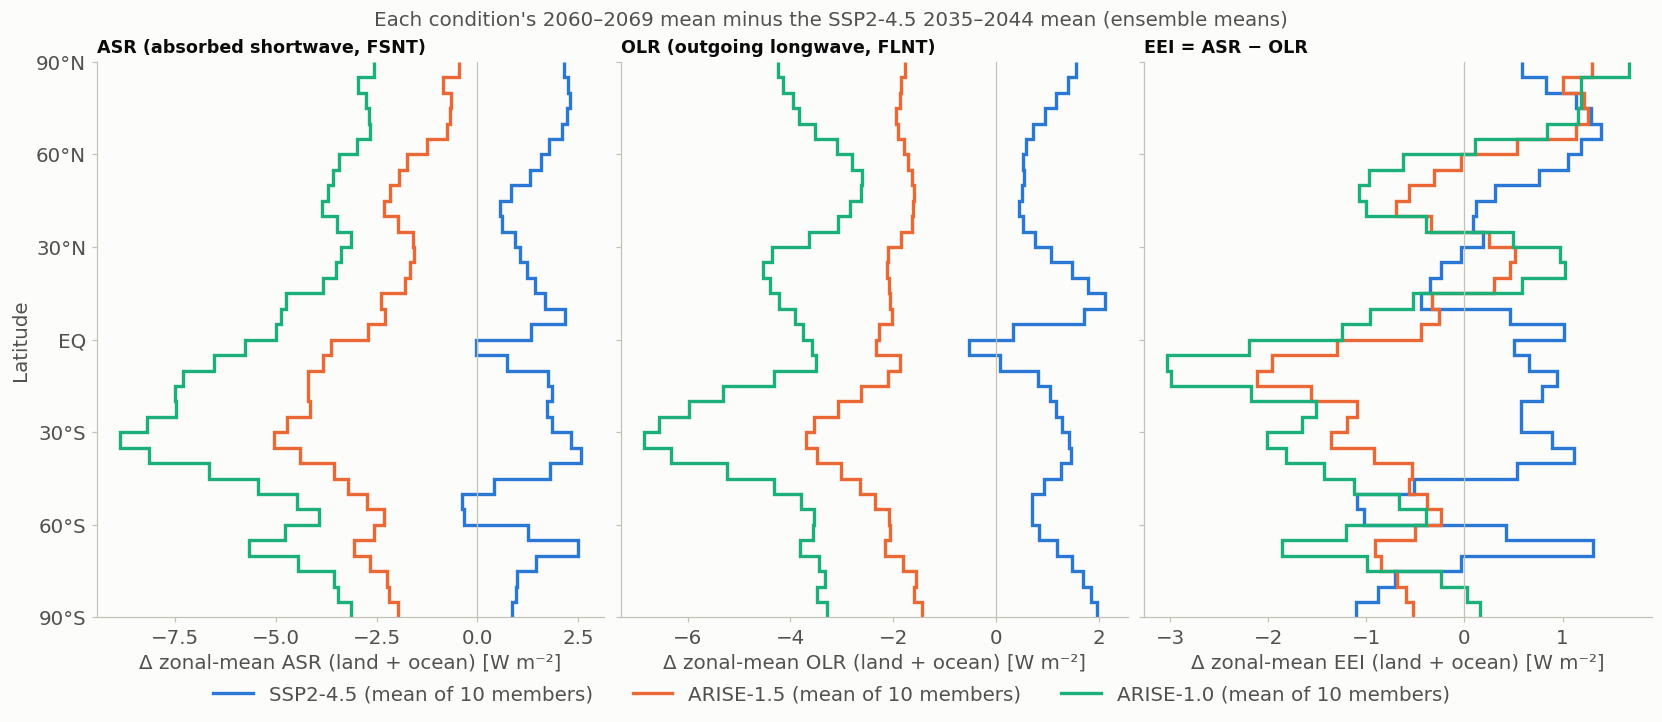

In [24]:
plot_toa_comparison(per_area=True, years=DIFF_YEARS, baseline=DIFF_BASELINE, **DIFF_STYLE)